# Part Two: Data Analysis
Answers all five provided questions and one independent investigation, using the cleaned dataset.
Every conclusion is backed by a plot and a statistical test, and `llcd_task2_solution.md` is generated from the numbers below.

Tests used (all rank-based, because settlement_index and the physical properties are skewed):
Kruskal-Wallis (do groups differ?), Mann-Whitney with Bonferroni correction (which pairs differ?), Spearman rho (monotonic trend).
Effect size for groups = the share of the variance of settlement_index that the grouping explains (eta squared).

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import f as f_dist, kruskal, mannwhitneyu, spearmanr

TEAM = "llcd"
PLOTS = Path(f"{TEAM}_task2_plots")
PLOTS.mkdir(exist_ok=True)

df = pd.read_csv(f"{TEAM}_cleaned_dataset.csv")
raw = pd.read_csv("dataset/Task2/train.csv")
assert (raw.planetId == df.planetId).all()          # cleaning never drops or reorders rows
y = df.settlement_index
print(f"{len(df)} planets, settlement_index mean {y.mean():.1f}, sd {y.std():.1f}, range {y.min():.1f}-{y.max():.1f}")


def pf(p):
    return "p < 1e-300" if p < 1e-300 else f"p = {p:.2g}"


def strength(r):
    a = abs(r)
    return "negligible" if a < .1 else "weak" if a < .3 else "moderate" if a < .5 else "strong"


def verdict(p):
    return f"significant ({pf(p)})" if p < 0.05 else f"not significant ({pf(p)})"


def by_group(g, name, title):
    """Per-group table + box plot + group means with 95% CI; returns (table, kruskal p, eta squared)."""
    d = pd.DataFrame({"g": g, "y": y}).dropna()
    t = d.groupby("g").y.agg(n="size", mean="mean", median="median", sd="std")
    t["ci95"] = 1.96 * t.sd / np.sqrt(t.n)
    t = t.sort_values("mean")
    samples = [d.y[d.g == k] for k in t.index]
    p = kruskal(*samples).pvalue
    eta2 = (t.n * (t["mean"] - d.y.mean()) ** 2).sum() / ((d.y - d.y.mean()) ** 2).sum()
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2]})
    a.boxplot(samples, showmeans=True)
    a.set_xticks(range(1, len(t) + 1), [f"{k}\n(n={n})" for k, n in zip(t.index, t.n)], rotation=40, ha="right")
    a.set(ylabel="settlement_index", title=title)
    b.errorbar(t["mean"], range(len(t)), xerr=t.ci95, fmt="o", capsize=3)
    b.set_yticks(range(len(t)), t.index)
    b.set(xlabel="mean settlement_index (95% CI)", title="Group means")
    fig.suptitle(f"Kruskal-Wallis {pf(p)}; grouping explains {eta2:.1%} of the variance")
    fig.tight_layout()
    fig.savefig(PLOTS / f"{name}.png", dpi=120)
    plt.show()
    return t, p, eta2


def pairwise(g):
    """Bonferroni-adjusted Mann-Whitney p-value for every pair of groups."""
    pairs = list(combinations(g.dropna().unique(), 2))
    return pd.DataFrame([(a, b, y[g == a].mean() - y[g == b].mean(), min(1, mannwhitneyu(y[g == a], y[g == b]).pvalue * len(pairs)))
                         for a, b in pairs], columns=["A", "B", "mean_diff", "p_adj"])


def trend(x, ok, ax, label, bins=10):
    """Scatter + equal-count bin means (95% CI) of y against x on the rows `ok`; returns (rho, p, bin table)."""
    xs, ys = x[ok], y[ok]
    rho, p = spearmanr(xs, ys)
    b = pd.qcut(xs.rank(method="first"), bins, labels=False)
    t = pd.DataFrame({"x": xs, "y": ys, "b": b}).groupby("b").agg(x=("x", "median"), m=("y", "mean"), sd=("y", "std"), n=("y", "size"))
    ax.scatter(xs, ys, s=3, alpha=.15, c="grey")
    ax.errorbar(t.x, t.m, yerr=1.96 * t.sd / np.sqrt(t.n), fmt="o-", c="red", capsize=3, label="bin means (95% CI)")
    ax.set(xlabel=label, ylabel="settlement_index", title=f"Spearman rho = {rho:.2f} ({pf(p)}, n = {ok.sum()})")
    return rho, p, t

6400 planets, settlement_index mean 59.2, sd 10.8, range 30.2-98.0


## Q1. Primary hazard vs settlement potential

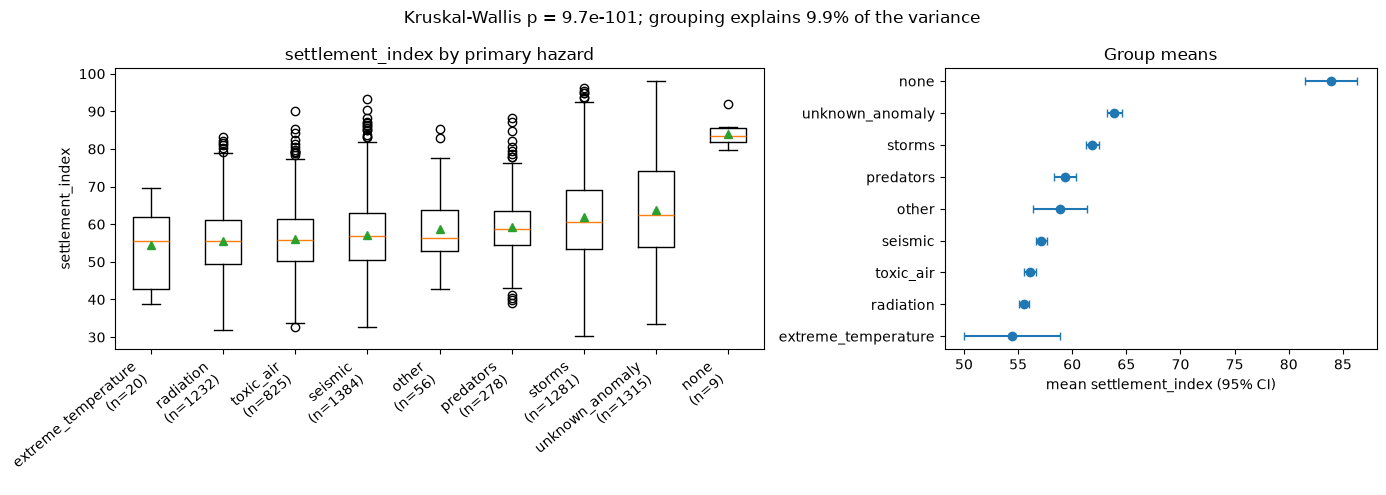

                        n   mean  median     sd  ci95
g                                                    
extreme_temperature    20  54.46   55.57  10.13  4.44
radiation            1232  55.54   55.57   8.48  0.47
toxic_air             825  56.10   55.69   8.45  0.58
seismic              1384  57.16   56.90   9.53  0.50
other                  56  58.85   56.24   9.58  2.51
predators             278  59.35   58.84   8.45  0.99
storms               1281  61.84   60.70  11.11  0.61
unknown_anomaly      1315  63.87   62.50  12.70  0.69
none                    9  83.90   83.35   3.71  2.42


In [2]:
t1, p1, eta1 = by_group(df.primary_hazard, "q1_hazard", "settlement_index by primary hazard")
print(t1.round(2).to_string())

## Q2. Oxygen, CO2 and methane vs settlement potential
Only planets whose value was actually recorded are used (rows where cleaning had to fill the value in are left out, so the
filled-in values cannot create a trend of their own).

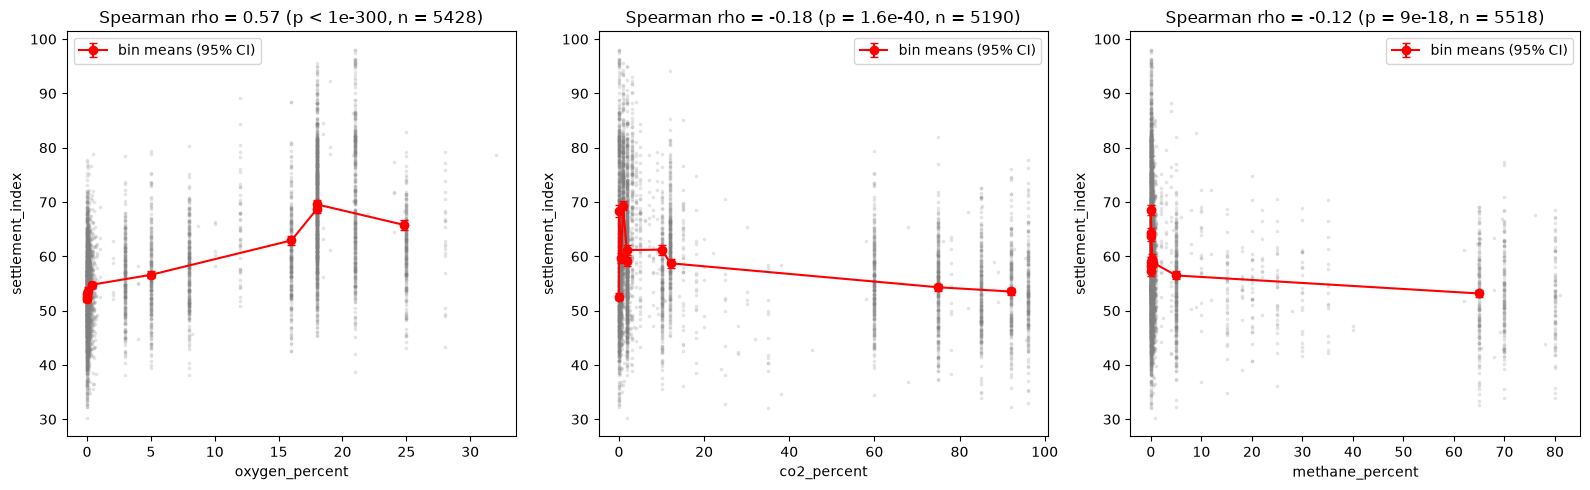

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
q2 = {}
for ax, c in zip(axes, ["oxygen_percent", "co2_percent", "methane_percent"]):
    q2[c] = trend(df[c], raw[c].notna(), ax, c)
    ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "q2_gases.png", dpi=120)
plt.show()

## Q3. Stellar multiplicity vs settlement potential
`star_type` is grouped by what it says about multiplicity: names containing "binary" are binary, "triple star system" is triple,
"brown dwarf companion" (a star with a substellar companion) is its own group, labels that cleaning merged into `other` cannot be
classified, and a star type given without any multiplicity wording is treated as a single star.

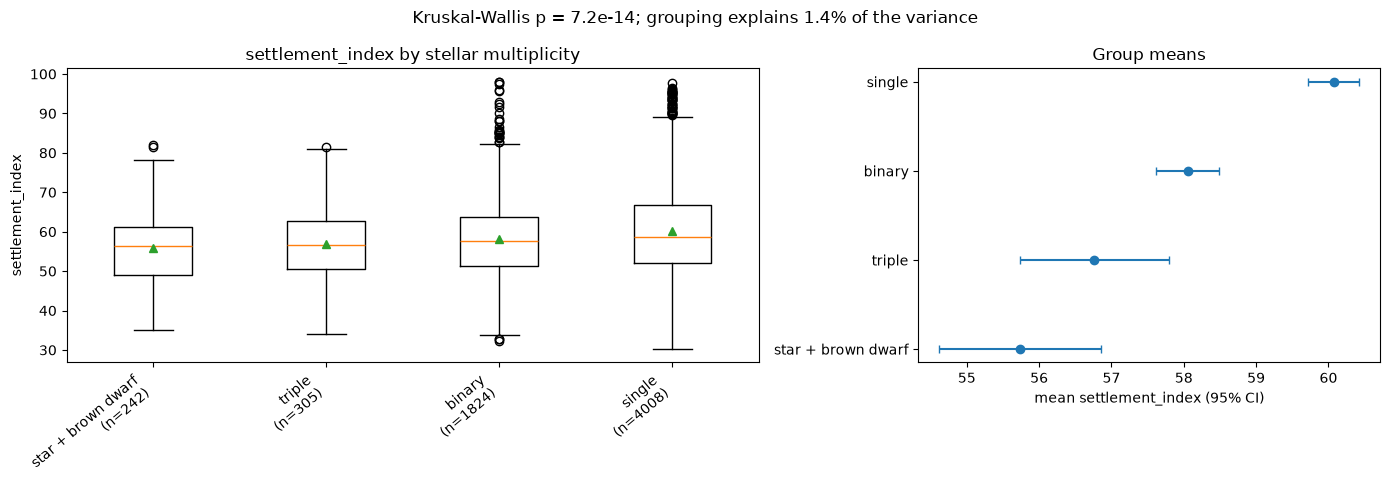

                       n   mean  median     sd  ci95
g                                                   
star + brown dwarf   242  55.74   56.43   8.89  1.12
triple               305  56.76   56.69   9.15  1.03
binary              1824  58.05   57.52   9.59  0.44
single              4008  60.07   58.71  11.37  0.35 
                  A                  B  mean_diff  p_adj
            single             binary     2.0182 0.0000
            single star + brown dwarf     4.3298 0.0000
            single             triple     3.3078 0.0001
            binary star + brown dwarf     2.3116 0.0089
            binary             triple     1.2896 0.3270
star + brown dwarf             triple    -1.0220 1.0000


In [4]:
def multiplicity(s):
    if "binary" in s:
        return "binary"
    return {"triple star system": "triple", "brown dwarf companion": "star + brown dwarf", "other": "unclassified (other)"}.get(s, "single")


mult = df.star_type.map(multiplicity).where(lambda m: m != "unclassified (other)")      # unclassified rows are left out
t3, p3, eta3 = by_group(mult, "q3_multiplicity", "settlement_index by stellar multiplicity")
pw3 = pairwise(mult)
print(t3.round(2).to_string(), "\n", pw3.round(4).to_string(index=False))

## Q4. Moons and rings vs settlement potential

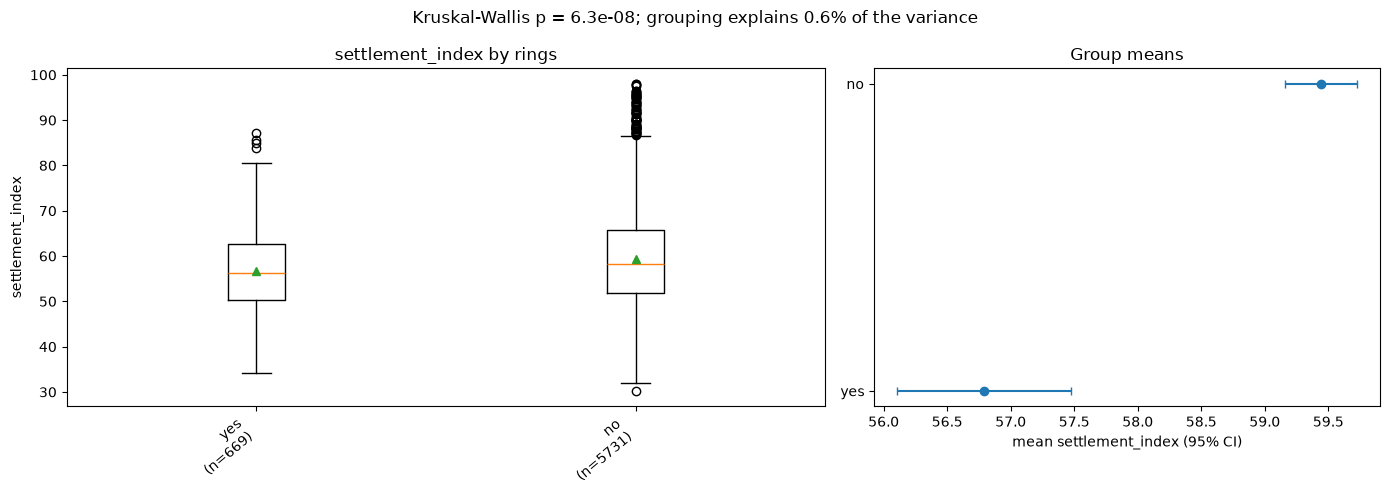

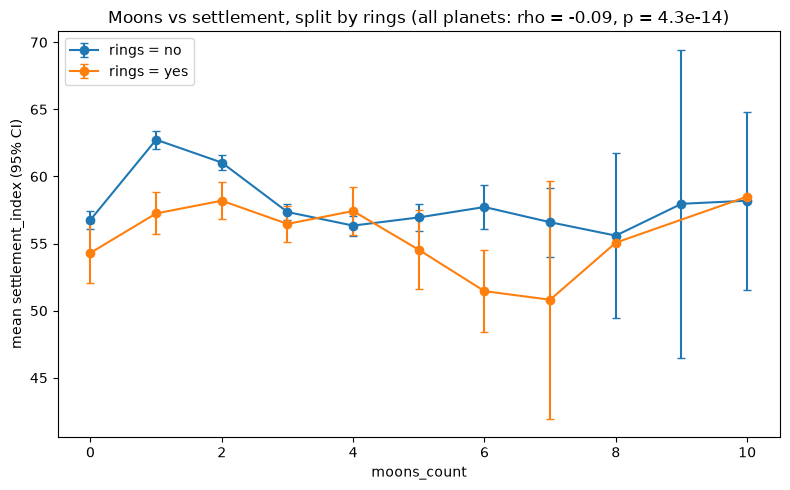

moons vs index: rho = -0.094 (p = 4.3e-14); rings=no rho = -0.097, rings=yes rho = -0.036
        n   mean  median     sd  ci95
g                                    
yes   669  56.79   56.15   9.05  0.69
no   5731  59.44   58.21  10.93  0.28


In [5]:
rho4, pr4 = spearmanr(df.moons_count, y)
t4, p4, eta4 = by_group(df.rings, "q4_rings", "settlement_index by rings")
fig, ax = plt.subplots(figsize=(8, 5))
rho_r = {}
for r, c in (("no", "tab:blue"), ("yes", "tab:orange")):
    s = df[df.rings == r]
    m = s.groupby("moons_count").settlement_index.agg(["mean", "std", "size"])
    ax.errorbar(m.index, m["mean"], yerr=1.96 * m["std"] / np.sqrt(m["size"]), fmt="o-", c=c, capsize=3, label=f"rings = {r}")
    rho_r[r] = spearmanr(s.moons_count, s.settlement_index)
ax.set(xlabel="moons_count", ylabel="mean settlement_index (95% CI)", title=f"Moons vs settlement, split by rings (all planets: rho = {rho4:.2f}, {pf(pr4)})")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "q4_moons_rings.png", dpi=120)
plt.show()
print(f"moons vs index: rho = {rho4:.3f} ({pf(pr4)}); rings=no rho = {rho_r['no'][0]:.3f}, rings=yes rho = {rho_r['yes'][0]:.3f}")
print(t4.round(2).to_string())

## Q5. Rogue and tidally locked planets vs the rest

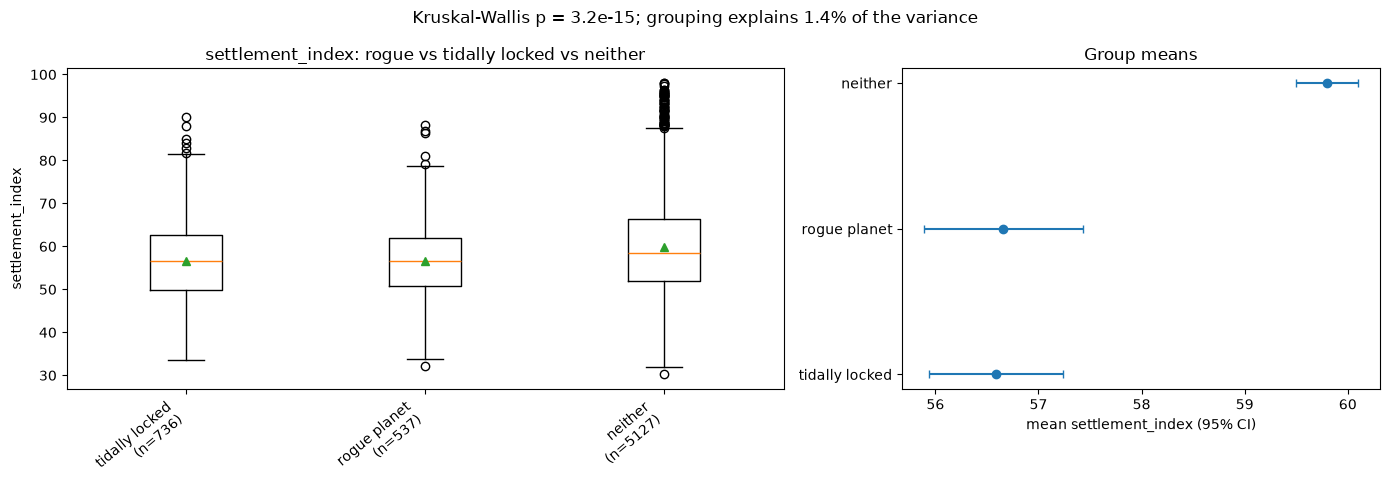

                   n   mean  median     sd  ci95
g                                               
tidally locked   736  56.59   56.68   9.03  0.65
rogue planet     537  56.66   56.56   9.13  0.77
neither         5127  59.80   58.46  11.07  0.30 
            A              B  mean_diff  p_adj
rogue planet        neither    -3.1397    0.0
rogue planet tidally locked     0.0704    1.0
     neither tidally locked     3.2101    0.0


In [6]:
grp = pd.Series(np.select([df.planet_type == "rogue planet", df.planet_type == "tidally locked"], ["rogue planet", "tidally locked"], "neither"), index=df.index)
t5, p5, eta5 = by_group(grp, "q5_rogue_tidally_locked", "settlement_index: rogue vs tidally locked vs neither")
pw5 = pairwise(grp)
print(t5.round(2).to_string(), "\n", pw5.round(4).to_string(index=False))

## Independent investigation: is there a "Goldilocks" property?
**Question:** which physical property of a planet (other than those in Q1-Q5) shapes settlement potential the most, and is it a
"more is better" relationship or a *Goldilocks* optimum, where intermediate values are best and both extremes are worse?

**Method:** for every remaining numeric property, compare how much of the variance of settlement_index is explained by a
*monotonic* relationship (Spearman rho squared) with how much is explained by *any* shape (means of 12 equal-count bins, eta squared).
A large gap means the effect is non-monotonic. The strongest property is then examined in detail, with an F-test of a quadratic
curve against a straight line (fitted on the percentile rank of the property, so heavy tails cannot dominate).
Only recorded (not filled-in) values are used for each property.

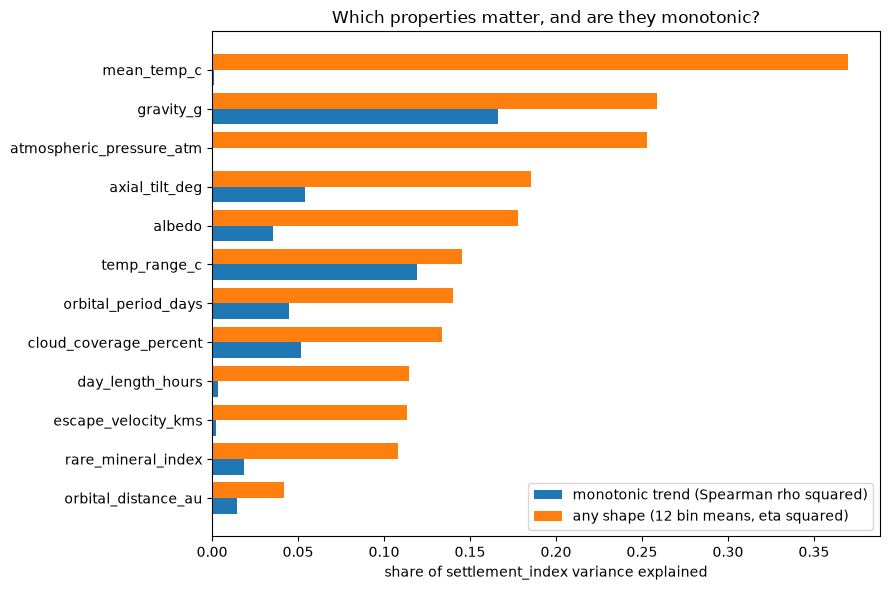

                 feature  monotonic_R2  any_shape_eta2    n   gap
             mean_temp_c         0.001           0.370 6400 0.369
               gravity_g         0.166           0.258 6400 0.092
atmospheric_pressure_atm         0.000           0.253 6400 0.253
          axial_tilt_deg         0.054           0.185 6352 0.131
                  albedo         0.036           0.178 6400 0.142
            temp_range_c         0.119           0.145 6400 0.026
     orbital_period_days         0.045           0.140 5761 0.095
  cloud_coverage_percent         0.052           0.134 6400 0.082
        day_length_hours         0.003           0.114 6344 0.111
     escape_velocity_kms         0.002           0.113 5758 0.111
      rare_mineral_index         0.019           0.108 6400 0.089
     orbital_distance_au         0.015           0.042 5763 0.028


In [7]:
used = {"settlement_index", "planetId", "oxygen_percent", "co2_percent", "methane_percent", "moons_count"}
feats = [c for c in df.select_dtypes("number") if c not in used and not c.endswith("_imputed")]
rows = []
for c in feats:
    ok = raw[c].notna()
    b = pd.qcut(df.loc[ok, c].rank(method="first"), 12, labels=False)
    m = y[ok].groupby(b).agg(["mean", "size"])
    eta = (m["size"] * (m["mean"] - y[ok].mean()) ** 2).sum() / ((y[ok] - y[ok].mean()) ** 2).sum()
    rows.append((c, spearmanr(df.loc[ok, c], y[ok])[0] ** 2, eta, ok.sum()))
scr = pd.DataFrame(rows, columns=["feature", "monotonic_R2", "any_shape_eta2", "n"]).assign(gap=lambda t: t.any_shape_eta2 - t.monotonic_R2)
scr = scr.sort_values("any_shape_eta2")
fig, ax = plt.subplots(figsize=(9, 6))
pos = np.arange(len(scr))
ax.barh(pos - .2, scr.monotonic_R2, .4, label="monotonic trend (Spearman rho squared)")
ax.barh(pos + .2, scr.any_shape_eta2, .4, label="any shape (12 bin means, eta squared)")
ax.set_yticks(pos, scr.feature)
ax.set(xlabel="share of settlement_index variance explained", title="Which properties matter, and are they monotonic?")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(PLOTS / "inv_screen.png", dpi=120)
plt.show()
print(scr.sort_values("any_shape_eta2", ascending=False).round(3).to_string(index=False))

mean_temp_c: rho = -0.03; quadratic vs line p < 1e-300; an interior optimum (Goldilocks); vertex at percentile 0.50 (value 12.5)
gravity_g: rho = 0.41; quadratic vs line p = 9.3e-46; a curved but essentially monotonic relationship (the quadratic's turning point is at or beyond the edge of the data); vertex at percentile 0.15 (value 0.336)
atmospheric_pressure_atm: rho = -0.00; quadratic vs line p = 1e-285; an interior optimum (Goldilocks); vertex at percentile 0.50 (value 1.03)


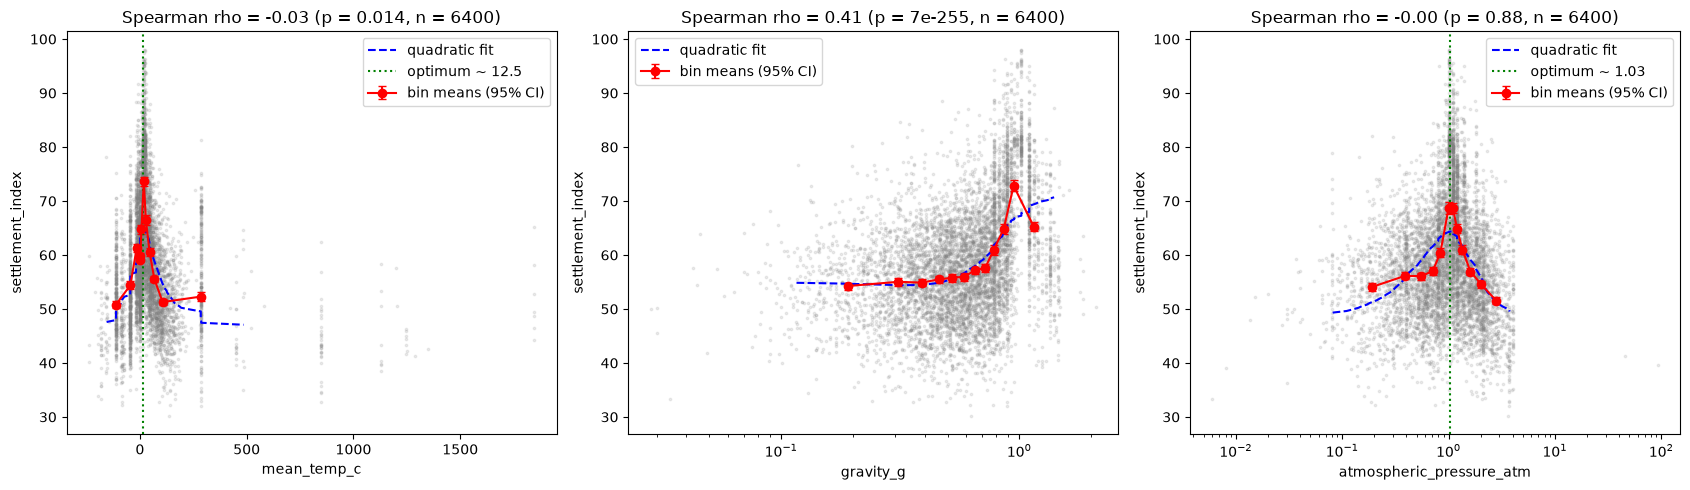

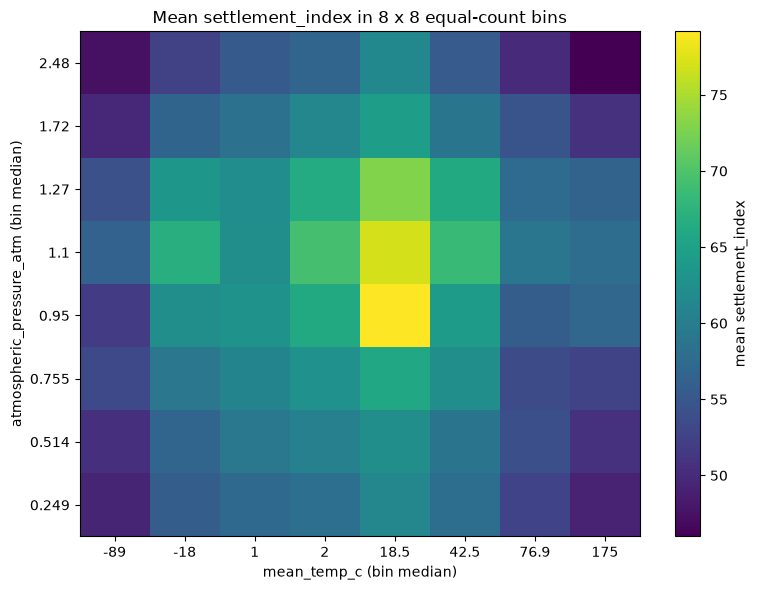

best region (79.2): mean_temp_c 13.5-28, atmospheric_pressure_atm 0.838-1.02; worst cell 46.0


In [8]:
sc = scr.set_index("feature")
tops = list(scr.feature.iloc[::-1][:3])                      # the three strongest properties
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
inv = {}
for ax, f in zip(axes, tops):
    ok = raw[f].notna()
    x, yy = df.loc[ok, f], y[ok]
    u = x.rank(pct=True)
    rss = lambda deg, u=u, yy=yy: np.sum((np.polyval(np.polyfit(u, yy, deg), u) - yy) ** 2)
    n = len(yy)
    p_quad = f_dist.sf((rss(1) - rss(2)) / (rss(2) / (n - 3)), 1, n - 3)
    c2 = np.polyfit(u, yy, 2)
    u_star = -c2[1] / (2 * c2[0])
    curved = p_quad < 0.01
    inside = bool(curved and 0.2 < u_star < 0.8)          # a real optimum/minimum must lie well inside the data, not at its edge
    shape = (("an interior optimum (Goldilocks)" if c2[0] < 0 else "an interior minimum (U-shape)") if inside else
             "a curved but essentially monotonic relationship (the quadratic's turning point is at or beyond the edge of the data)" if curved
             else "no significant curvature")
    x_star = np.quantile(x, np.clip(u_star, 0, 1))
    rho = trend(df[f], ok, ax, f, bins=12)[0]
    grid = np.linspace(0.01, 0.99, 200)
    ax.plot(np.quantile(x, grid), np.polyval(c2, grid), "b--", label="quadratic fit")
    if x.min() > 0 and x.max() / x.min() > 50:
        ax.set_xscale("log")
    if inside:
        ax.axvline(x_star, c="green", ls=":", label=f"optimum ~ {x_star:.3g}")
    ax.legend()
    inv[f] = dict(rho=rho, p_quad=p_quad, shape=shape, inside=inside, x_star=x_star, u_star=u_star, c2=c2)
    print(f"{f}: rho = {rho:.2f}; quadratic vs line {pf(p_quad)}; {shape}; vertex at percentile {u_star:.2f} (value {x_star:.3g})")
fig.tight_layout()
fig.savefig(PLOTS / "inv_top_features.png", dpi=120)
plt.show()

# the two most non-monotonic of those three, viewed together
f1, f2 = sorted(tops, key=lambda f: -sc.gap[f])[:2]
ok = raw[f1].notna() & raw[f2].notna()
d = pd.DataFrame({"a": df.loc[ok, f1], "b": df.loc[ok, f2], "y": y[ok]})
d["ia"], d["ib"] = (pd.qcut(d[c].rank(method="first"), 8, labels=False) for c in ("a", "b"))
H = d.pivot_table(index="ib", columns="ia", values="y", aggfunc="mean")
i, j = np.unravel_index(np.nanargmax(H.values), H.shape)
a_lo, a_hi = d.a[d.ia == H.columns[j]].agg(["min", "max"])
b_lo, b_hi = d.b[d.ib == H.index[i]].agg(["min", "max"])
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(H.values, origin="lower", cmap="viridis", aspect="auto")
ax.set(xticks=range(8), yticks=range(8), xticklabels=[f"{v:.3g}" for v in d.groupby("ia").a.median()],
       yticklabels=[f"{v:.3g}" for v in d.groupby("ib").b.median()], xlabel=f"{f1} (bin median)", ylabel=f"{f2} (bin median)",
       title="Mean settlement_index in 8 x 8 equal-count bins")
fig.colorbar(im, label="mean settlement_index")
fig.tight_layout()
fig.savefig(PLOTS / "inv_heatmap.png", dpi=120)
plt.show()
print(f"best region ({H.values[i, j]:.1f}): {f1} {a_lo:.3g}-{a_hi:.3g}, {f2} {b_lo:.3g}-{b_hi:.3g}; worst cell {np.nanmin(H.values):.1f}")

## Write the report (`llcd_task2_solution.md`)

In [9]:
def md(d):
    return "\n".join(["| " + " | ".join(map(str, d.columns)) + " |", "|" + "---|" * len(d.columns)]
                     + ["| " + " | ".join(map(str, r)) + " |" for r in d.round(2).itertuples(index=False)])


def groups_text(t, p, eta, name):
    hi, lo = t.index[-1], t.index[0]
    return (f"The mean settlement_index is highest for **{hi}** ({t.loc[hi, 'mean']:.1f}, n = {t.loc[hi, 'n']}) and lowest for **{lo}** "
            f"({t.loc[lo, 'mean']:.1f}, n = {t.loc[lo, 'n']}). The difference between the {name} groups is {verdict(p)} and the grouping "
            f"explains {eta:.1%} of the variance of settlement_index.")


def pair_text(pw):
    s = pw[pw.p_adj < 0.05].sort_values("p_adj")
    return ("After Bonferroni correction the significantly different pairs are: " + "; ".join(
        f"{r.A} vs {r.B} ({r.mean_diff:+.1f} points, {pf(r.p_adj)})" for r in s.itertuples()) + "."
            if len(s) else "After Bonferroni correction no pair of groups differs significantly.")


gas_text = "\n".join(
    f"- **{c}**: Spearman rho = {r:.2f}, a {strength(r)} {'positive' if r > 0 else 'negative'} association, {verdict(p)}; the decile means are highest around "
    f"{t.x[t.m.idxmax()]:.3g} % ({t.m.max():.1f}) and lowest around {t.x[t.m.idxmin()]:.3g} % ({t.m.min():.1f})."
    for c, (r, p, t) in q2.items())
ring_diff = t4.loc["yes", "mean"] - t4.loc["no", "mean"]
inv_text = "\n".join(
    f"- **{f}**: any-shape eta squared {sc.any_shape_eta2[f]:.1%} against {sc.monotonic_R2[f]:.1%} for a monotonic trend (Spearman rho = {v['rho']:.2f}); "
    f"quadratic vs straight line {pf(v['p_quad'])}; the data show {v['shape']}"
    + (f", located at about {v['x_star']:.3g} (percentile {v['u_star']:.0%})" if v["inside"] else "") + "." for f, v in inv.items())
joint_text = (f"Viewed together, {f1} and {f2} give the following picture: the highest-scoring bin pair (mean {H.values[i, j]:.1f}) has {f1} between "
              f"{a_lo:.3g} and {a_hi:.3g} and {f2} between {b_lo:.3g} and {b_hi:.3g}, while the worst bin pair averages {np.nanmin(H.values):.1f}.")
gold = [f for f, v in inv.items() if v["inside"] and v["c2"][0] < 0]
names = " and ".join([", ".join(gold[:-1]), gold[-1]] if len(gold) > 1 else gold)
concl = (f"The Goldilocks hypothesis is supported for {names}: settlement potential is best at intermediate values and falls off on both sides, "
         f"so a 'more is better' rule would misjudge {'these properties' if len(gold) > 1 else 'this property'}." if gold else
         "The Goldilocks hypothesis is not supported: none of the three strongest properties shows a significant interior optimum.")
rep = f"""# Task 2: Data analysis (team {TEAM})

All numbers and figures come from `{TEAM}_notebook_analysis.ipynb`, which analyses `{TEAM}_cleaned_dataset.csv` ({len(df)} planets; settlement_index mean {y.mean():.1f}, sd {y.std():.1f}). Group differences use Kruskal-Wallis and Bonferroni-corrected Mann-Whitney tests, trends use Spearman's rho; all are rank-based because the data are skewed. The data are observational, so every result is an association, not proof of cause, and planets that differ in one property also differ in others.

## Q1. How does the recorded primary hazard relate to settlement potential?
{groups_text(t1, p1, eta1, 'hazard')}

![Q1]({PLOTS}/q1_hazard.png)

{md(t1.reset_index().rename(columns={'g': 'primary_hazard'}))}

## Q2. How do atmospheric gas levels relate to settlement potential?
Only planets whose value was recorded (not filled in during cleaning) are used for each gas.

{gas_text}

![Q2]({PLOTS}/q2_gases.png)

## Q3. How does stellar multiplicity relate to settlement potential?
{groups_text(t3, p3, eta3, 'multiplicity')} {pair_text(pw3)} Star types that name no multiplicity were treated as single stars, and the few labels merged into `other` during cleaning could not be classified, so they are left out of this comparison.

![Q3]({PLOTS}/q3_multiplicity.png)

{md(t3.reset_index().rename(columns={'g': 'multiplicity'}))}

## Q4. How do moons and rings relate to settlement potential?
- **Moons:** Spearman rho = {rho4:.2f}, a {strength(rho4)} association, {verdict(pr4)}. Split by rings: rho = {rho_r['no'][0]:.2f} without rings and {rho_r['yes'][0]:.2f} with rings.
- **Rings:** planets with rings average {t4.loc['yes', 'mean']:.1f} versus {t4.loc['no', 'mean']:.1f} without ({ring_diff:+.1f} points); the difference is {verdict(p4)} and rings explain {eta4:.1%} of the variance.

![Q4 moons and rings]({PLOTS}/q4_moons_rings.png)
![Q4 rings]({PLOTS}/q4_rings.png)

## Q5. How do rogue and tidally locked planets compare with other planets?
{groups_text(t5, p5, eta5, 'planet-label')} {pair_text(pw5)} "Tidally locked" includes the variants (such as "tidally locked ocean world") that cleaning merged into that label.

![Q5]({PLOTS}/q5_rogue_tidally_locked.png)

{md(t5.reset_index().rename(columns={'g': 'group'}))}

## Independent investigation: is there a Goldilocks property?
**Question.** Which physical property (outside Q1-Q5) shapes settlement potential the most, and is the effect "more is better" or a Goldilocks optimum, where intermediate values are best?

**Method.** For each remaining numeric property I compared the variance of settlement_index explained by a monotonic trend (Spearman rho squared) with the variance explained by any shape (means of 12 equal-count bins). A large gap would mean a non-monotonic effect. The three strongest properties were then each fitted with a straight line and a quadratic curve and compared with an F-test (on percentile ranks, so heavy tails cannot dominate), and the two most non-monotonic ones were viewed together in a heatmap. Only recorded values were used.

![Screen]({PLOTS}/inv_screen.png)

**Result.** The three strongest properties are examined below. "Any-shape" is the variance explained by 12 bin means; a large excess over the monotonic share signals a non-monotonic effect.

{inv_text}

![Strongest properties]({PLOTS}/inv_top_features.png)

{joint_text}

![Joint view]({PLOTS}/inv_heatmap.png)

{md(scr.sort_values('any_shape_eta2', ascending=False).round(3))}

**Conclusion.** {concl}

## Limitations
Associations, not causes; the properties are correlated with each other (for example gases with planet type), so a trend in one may reflect another. Ten-plus comparisons were run, so a single p-value just under 0.05 should not be over-read. Cleaning choices (merged labels, `other` bucket, imputed values) can move individual group means slightly.
"""
Path(f"{TEAM}_task2_solution.md").write_text(rep, encoding="utf-8")
print(f"wrote {TEAM}_task2_solution.md")

wrote llcd_task2_solution.md
